# Final model test and crop result printout

This notebook is designed to give test statistics on final dog emotion classifier model, and to then predict emotions on given image files (i.e. cropped images from M & Ms model).

Note that due to colab fun-ness and the use of the 'colab.files' package, it may be tricky to streamline this for use in combined model.

Also, lots of image processing, so use a gpu unless you have some paint which you would like to watch dry.

***Note: will have to import model as .pkl file, as well as the unlabeled images you want to run model on.***

Hopefully will get both parts of model to play nicely sometime.

In [13]:
# Dependencies as per
import shutil
import zipfile
from contextlib import redirect_stdout
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import torch
from fastai.vision.all import *
from google.colab import files as colab_files
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import math
from PIL import Image

print("Finished loading packages")

Finished loading packages


In [14]:
# image processing: better use a gpu
if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU available. Using CPU.")

GPU available: Tesla T4
CUDA version: 13.0


In [15]:
# upload model

######################
## Upload .pkl file ##
## of model want to ##
##### test: here #####
######################
uploaded_model = colab_files.upload() # makesure to upload .pkl file here


learner_path = next(iter(uploaded_model)) # get file path
learn = load_learner(learner_path) # set load learner as learn
learn.model.float()

print(f'model loaded as {learner_path}')

Saving dog_emotion_model_densenet121_final_final.pkl to dog_emotion_model_densenet121_final_final (2).pkl
model loaded as dog_emotion_model_densenet121_final_final (2).pkl


/usr/local/lib/python3.13/dist-packages/fastai/learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


In [16]:
# get test dataset and
danielshanbalico_dog_emotion_path = kagglehub.dataset_download('danielshanbalico/dog-emotion')
print(danielshanbalico_dog_emotion_path)
mohitagarwal17_dog_img_path = kagglehub.dataset_download('mohitagarwal17/dog-img')
mohitagarwal17_dog_emotion_classifier_89_accuracy_other_default_1_path = kagglehub.model_download('mohitagarwal17/dog-emotion-classifier-89-accuracy/Other/default/1')

searches = 'angry','happy','relaxed','sad'
path = Path(danielshanbalico_dog_emotion_path)

# Load the CSV containing the selected filenames
csv_url = "https://raw.githubusercontent.com/Sincanator/Group-Sprint-2/refs/heads/main/Data/emotion_classifier_data_from_kaggle/final_test_split.csv"
df = pd.read_csv(csv_url)

# Create files list using only filenames in CSV
test_files = [path / filename for filename in df["filename"]]

print(f"Number of images in subset: {len(test_files)}")

Using Colab cache for faster access to the 'dog-emotion' dataset.
/kaggle/input/dog-emotion
Using Colab cache for faster access to the 'dog-img' dataset.
Number of images in subset: 400


In [17]:
# run testing (~ 4 mins dor our model)
test_dl = learn.dls.test_dl(test_files, with_labels=True)
loss, err = learn.validate(dl=test_dl)
accuracy = (1-err)*100
print(f"Test Images: {len(test_files)}")
print(f"Correct Predictions: {round(accuracy*len(test_files)/100)}")
print(f"Incorrect Predictions: {len(test_files)-round(accuracy*len(test_files)/100)}")
print(f"Accuracy: {accuracy:.2f}%")

Test Images: 400
Correct Predictions: 349
Incorrect Predictions: 51
Accuracy: 87.25%


In [18]:
# plotting test figures and stuff (takes long time to run so maybe don't include / run once and save output)

#interp = ClassificationInterpretation.from_learner(learn, dl=test_dl)
#interp.print_classification_report()
#interp.plot_top_losses(9, figsize=(18,12))
#interp.plot_confusion_matrix(figsize=(4,4))

<div><progress max="25" value="1"></progress> 4.00% [1/25 00:08&lt;03:12]</div>

KeyboardInterrupt: 

In [19]:
# upload unlabeled images (~ 1 min per 100 images)

######################
## Upload unlabeled ##
## image(/s) to run ##
### through model ####
######################
non_labeled = colab_files.upload()

print(f'uploaded the images')

vocab = list(learn.dls.vocab)

Saving __dog_1_0.940.jpg to __dog_1_0.940 (1).jpg
Saving _-2_dog_1_0.807.jpg to _-2_dog_1_0.807 (1).jpg
Saving _-2_dog_2_0.670.jpg to _-2_dog_2_0.670 (1).jpg
Saving 53918_dog_1_0.936.jpg to 53918_dog_1_0.936 (1).jpg
Saving 53929_dog_1_0.895.jpg to 53929_dog_1_0.895 (1).jpg
Saving 105623553758618644_dog_1_0.886.jpg to 105623553758618644_dog_1_0.886 (1).jpg
Saving 105623553758618644_dog_2_0.686.jpg to 105623553758618644_dog_2_0.686 (1).jpg
Saving 392728030013770338_dog_1_0.676.jpg to 392728030013770338_dog_1_0.676 (1).jpg
Saving 392728030013770338_dog_2_0.606.jpg to 392728030013770338_dog_2_0.606 (1).jpg
Saving 392728030013770338_dog_3_0.595.jpg to 392728030013770338_dog_3_0.595 (1).jpg
Saving 392728030013770338_dog_4_0.562.jpg to 392728030013770338_dog_4_0.562 (1).jpg
Saving 454371049900392346_dog_1_0.948.jpg to 454371049900392346_dog_1_0.948 (1).jpg
Saving 458170962114035932_dog_1_0.808.jpg to 458170962114035932_dog_1_0.808 (1).jpg
Saving 541206080205504001_dog_1_0.954.jpg to 541206080

In [20]:
# get predictions on unlabeled images (~30s per 100)
results = []
for img_name in non_labeled:
    img_path = Path(img_name)
    pred, pred_idx, probs = learn.predict(img_path)

    # map probabilities by class name so column order always matches learn.dls.vocab
    prob_by_class = {str(cls).lower(): float(probs[i]) for i, cls in enumerate(vocab)}

    results.append({
        "Image": img_path.name,
        "Predicted Emotion": str(pred),
        "Confidence": float(probs[int(pred_idx)]),
        "Angry": prob_by_class.get("angry", float("nan")),
        "Happy": prob_by_class.get("happy", float("nan")),
        "Relaxed": prob_by_class.get("relaxed", float("nan")),
        "Sad": prob_by_class.get("sad", float("nan")),
    })

predictions_df = pd.DataFrame(results).sort_values("Confidence", ascending=False)



In [22]:
# diagnostics from predictions_df
total_imgs = len(predictions_df)
print(f"Total predicted images: {total_imgs}")
print(f"Overall average confidence: {predictions_df['Confidence'].mean():.2%}\n")

# count and average confidence per predicted emotion
emotion_summary = (
    predictions_df.groupby("Predicted Emotion", as_index=False)
    .agg(
        Count=("Image", "count"),
        Avg_Confidence=("Confidence", "mean"),
    )
    .sort_values("Count", ascending=False)
)
emotion_summary["Share (%)"] = (emotion_summary["Count"] / total_imgs) * 100

for _, row in emotion_summary.iterrows():
    print(
        f"{row['Predicted Emotion']}: {int(row['Count'])} images "
        f"({row['Share (%)']:.1f}%) | Avg confidence: {row['Avg_Confidence']:.2%}"
    )

Total predicted images: 115
Overall average confidence: 90.99%

relaxed: 62 images (53.9%) | Avg confidence: 93.08%
happy: 23 images (20.0%) | Avg confidence: 89.11%
angry: 22 images (19.1%) | Avg confidence: 90.01%
sad: 8 images (7.0%) | Avg confidence: 82.86%


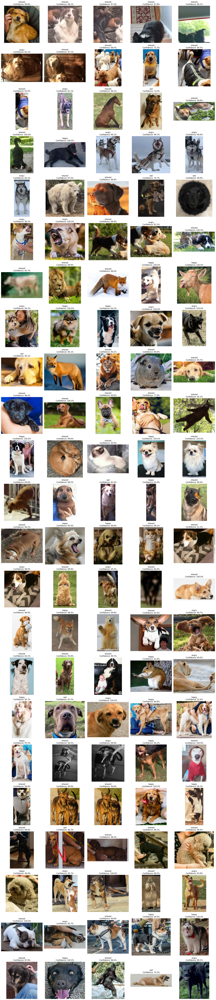

In [21]:
# display results (~15s per 100)
num_to_display = len(predictions_df)

items = list(non_labeled.keys()) if isinstance(non_labeled, dict) else list(non_labeled)
subset_files = [Path(p) for p in items[:num_to_display]]
n = len(subset_files)

ncols = 5
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(4 * ncols, 4 * nrows))
axes = np.array(axes).flatten()  # safely flattens whether 1D or 2D

for i, img_path in enumerate(subset_files):
    matches = predictions_df[
        predictions_df["Image"].apply(lambda x: Path(str(x)).name) == img_path.name]

    img = Image.open(img_path)
    axes[i].imshow(img)

    if not matches.empty:
        row = matches.iloc[0]
        axes[i].set_title(
            f"{row['Predicted Emotion']}\n"
            f"Confidence: {row['Confidence']:.1%}")
    else:
        axes[i].set_title(f"{img_path.name}\n(No prediction)")

    axes[i].axis("off")

# Hide any unused subplots
for j in range(n, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()
